[nltk_data] Downloading package punkt to /home/nineleaps/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/nineleaps/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Sample TF-IDF Features: ['arrived' 'average' 'bit' 'cold' 'delivery' 'driver' 'everything'
 'experience' 'fast' 'favorite' 'fine' 'food' 'great' 'hot' 'item' 'long'
 'missing' 'never' 'okay' 'perfect']
--- Traditional ML Model (Naive Bayes) Evaluation ---
Accuracy: 0.6519
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        20
           2       0.79      1.00      0.88        76
           3       1.00      1.00      1.00       298
           4       0.00      0.00      0.00       568
           5       0.56      1.00      0.72       727

    accuracy                           0.65      1689
   macro avg       0.47      0.60      0.52      1689
weighted avg       0.45      0.65      0.53      1689



/home/nineleaps/uber-eats-capstone/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nineleaps/uber-eats-capstone/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nineleaps/uber-eats-capstone/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

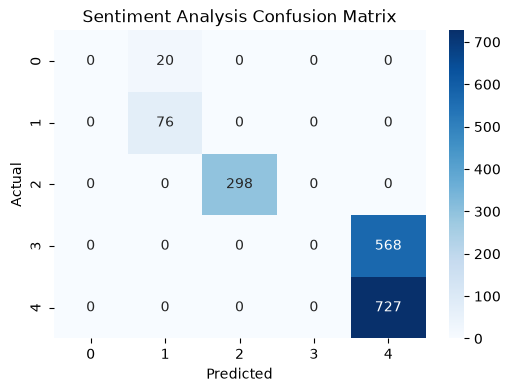

--- VADER Evaluation ---
VADER Accuracy: 0.0202
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.00      0.00      0.00        77
           2       0.05      0.42      0.09       406
           3       0.00      0.00      0.00      1558
           4       0.00      0.00      0.00      2889
           5       0.00      0.00      0.00      3515

    accuracy                           0.02      8445
   macro avg       0.01      0.07      0.01      8445
weighted avg       0.00      0.02      0.00      8445

--- Top Customer Complaints / Themes ---
['cold' 'food' 'item' 'long' 'missing' 'never' 'taste' 'terrible' 'took'
 'way']


/home/nineleaps/uber-eats-capstone/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nineleaps/uber-eats-capstone/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nineleaps/uber-eats-capstone/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{m

In [7]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import seaborn as sns

# Download required NLTK data (run once)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

# Load dataset (adjust path and column names based on your Day 1 synthetic data)
reviews_df = pd.read_csv('../data/reviews.csv')
# Assuming reviews_df has 'review_text' and 'sentiment' (e.g., Positive/Negative or 1/0) columns

# Part 1: Text Cleaning
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    if not isinstance(text, str):
        return ""
    # Lowercasing and punctuation removal
    text = re.sub(r'[^\w\s]', '', text.lower())
    # Tokenization
    tokens = word_tokenize(text)
    # Stop-word removal and lemmatization
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return ' '.join(cleaned_tokens)

reviews_df['cleaned_review'] = reviews_df['review_text'].apply(clean_text)

# Part 2: TF-IDF
tfidf = TfidfVectorizer(max_features=1000)
X_tfidf = tfidf.fit_transform(reviews_df['cleaned_review'])

# Extract important keywords
feature_names = tfidf.get_feature_names_out()
print(f"Sample TF-IDF Features: {feature_names[:20]}")

# Part 3: Sentiment Modeling
# Map categorical target to numeric if needed (e.g., Positive -> 1, Negative -> 0)
if reviews_df['rating_score'].dtype == 'O':
    reviews_df['target'] = reviews_df['rating_score'].map({'Positive': 1, 'Negative': 0, 'Neutral': 2})
else:
    reviews_df['target'] = reviews_df['rating_score']

X_train, X_test, y_train, y_test = train_test_split(X_tfidf, reviews_df['target'], test_size=0.2, random_state=42)

# Train Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred = nb_model.predict(X_test)

# Model Evaluation
print("--- Traditional ML Model (Naive Bayes) Evaluation ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Sentiment Analysis Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Part 4: VADER
analyzer = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05:
        return 1 # Positive
    elif score <= -0.05:
        return 0 # Negative
    else:
        return 2 # Neutral

# Apply VADER to original uncleaned text to capture emojis/punctuation
reviews_df['vader_prediction'] = reviews_df['review_text'].apply(get_vader_sentiment)

print("--- VADER Evaluation ---")
print(f"VADER Accuracy: {accuracy_score(reviews_df['target'], reviews_df['vader_prediction']):.4f}")
print(classification_report(reviews_df['target'], reviews_df['vader_prediction']))

# Part 5: Extract Business Insights (Top negative themes)
# Filter for 1-star and 2-star reviews instead of 0
negative_reviews = reviews_df[reviews_df['target'] <= 2]['cleaned_review']

# Drop any empty rows just to be safe
negative_reviews = negative_reviews.dropna()
negative_reviews = negative_reviews[negative_reviews.str.strip() != '']

# Fit the vectorizer and extract themes
neg_tfidf = TfidfVectorizer(max_features=10).fit(negative_reviews)
top_neg_themes = neg_tfidf.get_feature_names_out()

print("--- Top Customer Complaints / Themes ---")
print(top_neg_themes)